# 05 — Második intelligenciaréteg: tematikus kategorizálás / Layer 2: thematic categorisation

HU: Az első réteg megmondja, **milyen** egy mondat (negatív / semleges / pozitív). A második réteg két szinten
mondja meg, **miről** és **pontosan mi miatt**:

```
mondat ──► [1. réteg] szentiment (B)              → negatív / semleges / pozitív
       ──► [2/a] aspektus-osztályozó (HRAST, BERT) → MIRŐL szól?   pl. bathroom
       ──► [2/b] altémák (beágyazás + fürtözés)    → MI A GOND?    pl. „nincs meleg víz”
```

| # | Lépés / Step | Mérés / Measurement | Dolgozat / Thesis |
|---|---|---|---|
| 1 | 2/a tanítás a HRAST-on / training on HRAST | aspektusonkénti F1 a HRAST-teszten, vs. kulcsszólista | 3.4, 3.5 |
| 2 | 2/a alkalmazás a Booking-mondatokra / applying to Booking | egyezés a kulcsszólistával | 3.5 |
| 3 | 2/b altémák aspektusonként / subtopics per aspect | NPMI-koherencia, diverzitás, stabilitás (ARI) | 3.4, 3.5 |
| 4 | Panasztérkép / complaint map | lift szegmensenként | 3.5 |
| 5 | Kézi ellenőrzés / manual check | témánkénti pontosság | 3.5 |

**Előfeltétel / Prerequisites:** a (B) modell (`results/models/approach_b_hrast`), a HRAST CSV a `data/raw/hrast/`
mappában, és `pip install sentence-transformers umap-learn`.
**Elemzési egység / Analysis unit:** tagmondat, a dicséret- és panaszmezőből KÜLÖN bontva / clause, split SEPARATELY
from the praise and complaint fields. GPU ajánlott (a 2/a tanítás kb. 10–15 perc).

## 1. Környezet és adatok / Environment and data

In [1]:
# HU: A notebooks/ mappából futunk, ezért a szülőmappát a path-hoz adjuk (src csomag).
# EN: We run from the notebooks/ folder, so the parent folder is added to the path (src package).
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, APPROACHES, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import evaluation as ev
from src import descriptives as ds
from src import aspects as asp
from src import aspect_model as am
from src import topic_modeling as tm
from src import pipeline

# HU: Reprodukálhatóság + egységes ábrastílus. / EN: Reproducibility + uniform figure style.
set_seed()
PATHS.ensure()
apply_plot_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

# HU: ELEMZÉSI EGYSÉGEK: a dicséret- és a panaszmezőt KÜLÖN bontjuk tagmondatokra (pont, pontosvessző,
#     "but / however / although" mentén), így a kettő nem olvad egy "mondatba". A dicséretmezőben a
#     vesszős felsorolásokat is szétbontjuk (CFG.split_praise_lists). Minden egységre lefut a
#     (B) modell is (kb. 5–10 perc, darabolva, folytatható).
# EN: ANALYSIS UNITS: the praise and the complaint field are split into clauses SEPARATELY (at full stops,
#     semicolons, "but / however / although"), so the two never merge into one "sentence". In the praise
#     field comma enumerations are split too (CFG.split_praise_lists). The (B) model also runs on every
#     unit (about 5–10 min, chunked, resumable).
from src import bert_labelling as bl
meta = ds.prepare_star_rating(dl.read_frame(pipeline.LABELLED))
units = pp.build_field_units(meta)
scorer_b = bl.TransformerScorer(str(PATHS.models / "approach_b_hrast"))
sent = bl.predict_units(units, "", "B", cache_name="B_field_units", scorer=scorer_b)

meta_cols = ["review_id", "score", "label_final", "accommodation_type", "accommodation_country",
             "guest_type", "accommodation_star_rating"]
sent = sent.merge(meta[[c for c in meta_cols if c in meta.columns]], on="review_id", how="left")
dl.write_frame(sent, PATHS.labels / "field_units_B")
print(f"{len(sent):,} units from {sent['review_id'].nunique():,} reviews")

# HU: Mezőpolaritás × (B)-címke: mennyire ért egyet a modell a vendég saját besorolásával?
# EN: Field polarity × (B) label: how far does the model agree with the guest's own classification?
display(pd.crosstab(sent["field_polarity"], sent["B_label"], normalize="index").round(3))

18:23:44 | INFO    | src.preprocessing | Field units: 1100650 from 203079 reviews | by field: {'positive': 827008, 'negative': 273642}
18:24:11 | INFO    | src.bert_labelling | Loading model: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast (device: cuda, fp16: True)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

18:24:16 | INFO    | src.bert_labelling | Model type: 3class | labels: ['negative', 'neutral', 'positive']
18:24:16 | WARNING | src.bert_labelling | Cache 'B_field_units' is stale (input or model changed) — recomputing.
18:24:16 | INFO    | src.bert_labelling | [B_field_units] chunk 1/111 (10000 texts)
18:24:20 | INFO    | src.bert_labelling |   C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast: 50/157 batches (907 texts/s)
18:24:22 | INFO    | src.bert_labelling |   C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast: 100/157 batches (1097 texts/s)
18:24:24 | INFO    | src.bert_labelling |   C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast: 150/157 batches (1164 texts/s)
18:24:25 | INFO    | src.bert_labelling | [B_field_units] chunk 2/111 (10000 texts)
18:24:27 | INFO    | src.bert_labelling |   C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\COD

1,100,650 units from 203,079 reviews


B_label,negative,neutral,positive
field_polarity,,,
negative,0.740,0.079,0.181
positive,0.067,0.049,0.884


## 2. 2/a — Aspektus-osztályozó a HRAST-on / Aspect classifier on HRAST

HU: Többcímkés BERT: aspektusonként egy igen/nem döntés (szigmoid). A ritka aspektusok nagyobb súlyt kapnak
(`pos_weight`), a döntési küszöböt aspektusonként a **validációs** halmazon hangoljuk, a végső mérés a **teszthalmazon**
történik — és ugyanott mérjük a kulcsszólistát is (alapvonal).

EN: Multi-label BERT: one yes/no decision per aspect (sigmoid). Rare aspects get a larger weight (`pos_weight`), the
decision threshold is tuned per aspect on the **validation** set, the final measurement is on the **test** set — where
the keyword list (baseline) is measured too.

In [2]:
hrast_raw = dl.load_hrast_raw()
asp_data, ASPECTS = am.prepare_hrast_aspects(hrast_raw)
counts = asp_data[ASPECTS].sum().sort_values(ascending=False).to_frame("sentences")
counts["share"] = (counts["sentences"] / len(asp_data)).round(4)
display(counts); ev.save_table(counts, "05_hrast_aspect_counts")

18:38:34 | INFO    | src.data_loading | HRAST loaded: hrast.csv — 23113 rows, columns: ['id', 'review', 'Unnamed: 2', 'positive', 'negative', 'neutral', 'Clean', 'Comfort', 'Facilities/Amenities', 'Location', 'Restaurant (dinner)', 'Staff', 'View (Balcony)', 'Breakfast', 'Room', 'Pool', 'Beach', 'Bathroom/Shower (toilet)', 'Bar', 'Bed', 'Parking', 'Noise', 'Reception-checkin', 'Lift', 'Value for money', 'Wi-Fi', 'Generic', 'Aspect']
18:38:34 | INFO    | src.aspect_model | HRAST aspect data: 23105 sentences, 21 aspects | without aspect: 0.0%


,sentences,share
room,5004,0.2166
location,4727,0.2046
staff,3800,0.1645
cleanliness,2926,0.1266
facilities,2923,0.1265
comfort,2561,0.1108
breakfast,2539,0.1099
bathroom,2344,0.1014
generic,1973,0.0854
noise,1604,0.0694


18:38:34 | INFO    | src.evaluation | Table saved: 05_hrast_aspect_counts.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_hrast_aspect_counts.csv')

Aspect model already trained — loading the saved test results.


,precision,recall,f1,support
room,0.7927,0.7906,0.7917,769
location,0.9348,0.9556,0.9451,675
staff,0.9193,0.9597,0.9391,546
cleanliness,0.9417,0.9417,0.9417,446
facilities,0.8479,0.8064,0.8266,470
comfort,0.8282,0.8258,0.8270,356
breakfast,0.9280,0.9704,0.9488,372
bathroom,0.9520,0.9242,0.9379,343
generic,0.7085,0.7864,0.7454,309
noise,0.9466,0.9323,0.9394,266


,support,keyword_precision,keyword_recall,keyword_f1,model_precision,model_recall,model_f1,f1_gain
aspect,,,,,,,,
room,769,0.5673,0.8986,0.6955,0.7927,0.7906,0.7917,0.0961
location,675,0.9282,0.9007,0.9143,0.9348,0.9556,0.9451,0.0308
staff,546,0.9022,0.8443,0.8723,0.9193,0.9597,0.9391,0.0668
facilities,470,0.5340,0.3511,0.4236,0.8479,0.8064,0.8266,0.4030
cleanliness,446,0.9332,0.7825,0.8512,0.9417,0.9417,0.9417,0.0905
breakfast,372,0.8589,0.9489,0.9017,0.9280,0.9704,0.9488,0.0471
bathroom,343,0.8963,0.9067,0.9014,0.9520,0.9242,0.9379,0.0364
noise,266,0.9755,0.7481,0.8468,0.9466,0.9323,0.9394,0.0926
value_for_money,136,0.6788,0.6838,0.6813,0.6894,0.8162,0.7475,0.0662


18:38:35 | INFO    | src.evaluation | Figure saved: 05_aspect_keyword_vs_model.png


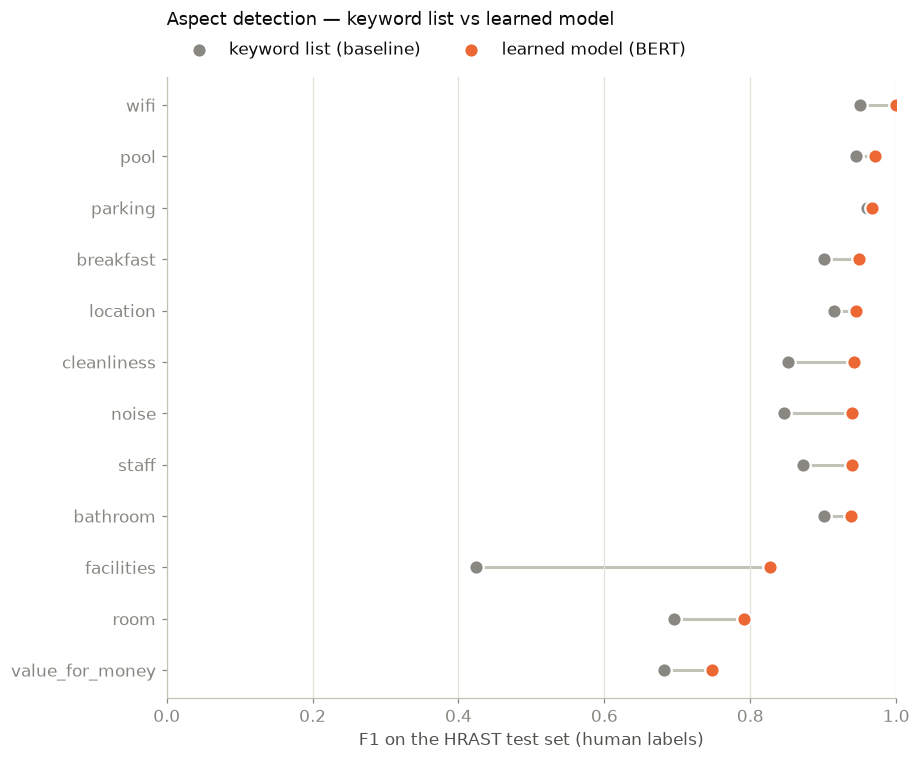

Mean F1 on the shared aspects — keyword: 0.829 | model: 0.913


In [3]:
# HU: Ha a modell már elkészült, nem tanítjuk újra (a mentett teszteredményt töltjük be).
# EN: If the model already exists it is not retrained (the saved test results are loaded).
if not (am.DEFAULT_MODEL_DIR / "thresholds.json").exists():
    result = am.train_aspect_model(asp_data, ASPECTS)
    report, comparison = result["test_report"], result["keyword_comparison"]
    ev.save_table(report, "05_aspect_model_test_report")
    ev.save_table(comparison, "05_aspect_keyword_vs_model")
else:
    print("Aspect model already trained — loading the saved test results.")
    report = pd.read_csv(PATHS.tables / "05_aspect_model_test_report.csv", index_col=0)
    comparison = pd.read_csv(PATHS.tables / "05_aspect_keyword_vs_model.csv", index_col=0)

display(report)
display(comparison)
am.plot_keyword_vs_model(comparison, save_as="05_aspect_keyword_vs_model"); plt.show()
print(f"Mean F1 on the shared aspects — keyword: {comparison['keyword_f1'].mean():.3f} | "
      f"model: {comparison['model_f1'].mean():.3f}")

## 3. 2/a alkalmazása a Booking-mondatokra / Applying 2/a to the Booking sentences

HU: Darabolt, folytatható futás (mint a címkézésnél). Itt nincs emberi címke, ezért a kulcsszólistával való
**egyezést** mérjük (konzisztencia), nem a pontosságot.
EN: Chunked, resumable run (as in labelling). There is no human label here, so we measure **agreement** with the
keyword list (consistency), not accuracy.

In [4]:
sent_asp = am.predict_aspects(sent, cache_name="aspects_field_units")
dl.write_frame(sent_asp, PATHS.labels / "field_units_aspects")
ASPECT_NAMES = am.aspect_names_in(sent_asp)

share = sent_asp[[f"asp_{a}" for a in ASPECT_NAMES]].mean().sort_values(ascending=False)
share.index = share.index.str.replace("asp_", "", regex=False)
display(share.round(4).to_frame("share of sentences"))
print(f"Sentences without any aspect: {(sent_asp['n_aspects'] == 0).mean():.1%}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

18:38:38 | WARNING | src.bert_labelling | Cache 'aspects_field_units' is stale (input or model changed) — recomputing.
18:38:38 | INFO    | src.bert_labelling | [aspects_field_units] chunk 1/111 (10000 texts)
18:38:45 | INFO    | src.bert_labelling | [aspects_field_units] chunk 2/111 (10000 texts)
18:38:53 | INFO    | src.bert_labelling | [aspects_field_units] chunk 3/111 (10000 texts)
18:39:00 | INFO    | src.bert_labelling | [aspects_field_units] chunk 4/111 (10000 texts)
18:39:08 | INFO    | src.bert_labelling | [aspects_field_units] chunk 5/111 (10000 texts)
18:39:15 | INFO    | src.bert_labelling | [aspects_field_units] chunk 6/111 (10000 texts)
18:39:23 | INFO    | src.bert_labelling | [aspects_field_units] chunk 7/111 (10000 texts)
18:39:31 | INFO    | src.bert_labelling | [aspects_field_units] chunk 8/111 (10000 texts)
18:39:38 | INFO    | src.bert_labelling | [aspects_field_units] chunk 9/111 (10000 texts)
18:39:46 | INFO    | src.bert_labelling | [aspects_field_units] chunk 1

,share of sentences
location,0.2064
generic,0.1895
staff,0.1603
room,0.1425
facilities,0.0985
comfort,0.0921
breakfast,0.0921
cleanliness,0.0854
bathroom,0.0451
bed,0.0446


Sentences without any aspect: 4.1%


,mentions,mention_share,negative,neutral,positive,neg_lift,pos_lift
aspect,,,,,,,
lift,5971,0.0054,0.7503,0.0628,0.1869,3.2001,0.2637
bathroom,49626,0.0451,0.5162,0.0641,0.4197,2.2018,0.5921
wifi,6948,0.0063,0.5105,0.0535,0.4360,2.1773,0.6150
noise,37444,0.0340,0.4959,0.0283,0.4759,2.1149,0.6713
facilities,108410,0.0985,0.3781,0.0786,0.5433,1.6126,0.7665
reception,34296,0.0312,0.3407,0.0585,0.6008,1.4533,0.8475
value_for_money,37771,0.0343,0.3202,0.0731,0.6067,1.3658,0.8559
parking,17674,0.0161,0.3182,0.0598,0.6220,1.3569,0.8775
bed,49121,0.0446,0.2783,0.0400,0.6817,1.1868,0.9617


18:53:01 | INFO    | src.evaluation | Table saved: 05_aspect_sentiment_model.csv
18:53:03 | INFO    | src.evaluation | Figure saved: 05_aspect_sentiment_model.png


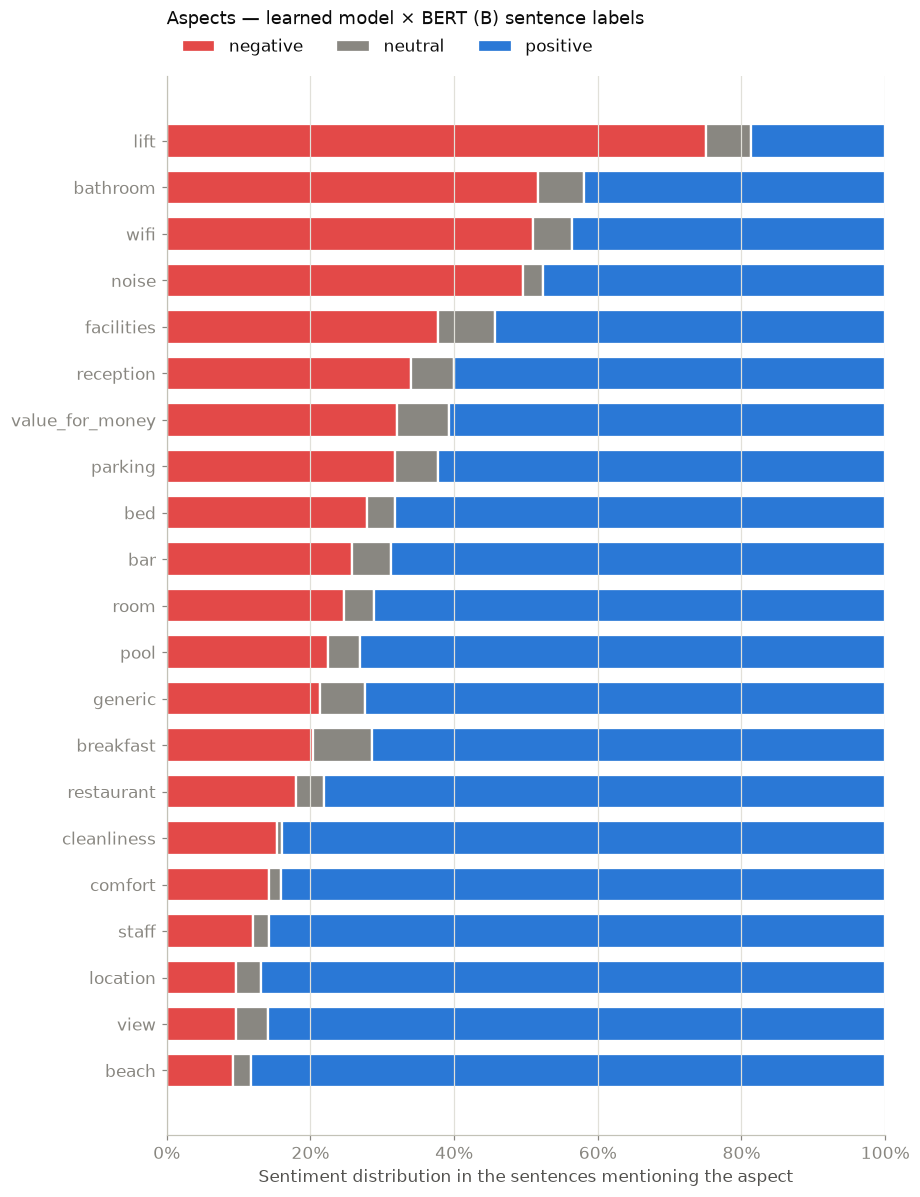

,share_model,share_keyword,agreement,cohen_kappa
aspect,,,,
location,0.2068,0.1498,0.9266,0.7510
staff,0.1615,0.1032,0.9300,0.6973
room,0.1419,0.1861,0.8873,0.5903
facilities,0.0965,0.0566,0.9046,0.3288
breakfast,0.0910,0.0935,0.9673,0.8049
cleanliness,0.0838,0.0759,0.9869,0.9109
bathroom,0.0453,0.0438,0.9874,0.8520
noise,0.0352,0.0283,0.9911,0.8547
value_for_money,0.0349,0.0305,0.9852,0.7669


18:53:07 | INFO    | src.evaluation | Table saved: 05_aspect_keyword_agreement_booking.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_aspect_keyword_agreement_booking.csv')

In [5]:
# HU: Aspektus × szentiment a TANULT aspektusokkal (vö. 04-es notebook: kulcsszavas változat).
# EN: Aspect × sentiment with the LEARNED aspects (cf. notebook 04: keyword version).
aspect_sent = asp.aspect_sentiment_table(sent_asp, label_col="B_label", aspects=ASPECT_NAMES,
                                         prefix="asp_", min_count=100)
display(aspect_sent); ev.save_table(aspect_sent, "05_aspect_sentiment_model")
asp.plot_aspect_sentiment(aspect_sent, "Aspects — learned model × BERT (B) sentence labels",
                          save_as="05_aspect_sentiment_model"); plt.show()

agreement = am.keyword_agreement(sent_asp.sample(min(50_000, len(sent_asp)), random_state=CFG.random_seed))
display(agreement); ev.save_table(agreement, "05_aspect_keyword_agreement_booking")

## 4. 2/b — Altémák aspektusonként / Subtopics per aspect

HU: A választott szentimentű (alapból **negatív**) mondatokon minden aspektusra külön témamodell: Sentence-BERT
beágyazás → UMAP → HDBSCAN → c-TF-IDF. A dicséretek altémáihoz állítsd `SENTIMENT = "positive"`-ra, és futtasd
újra innen (a fájlnevek a szentimentet is tartalmazzák).
EN: On sentences of the chosen sentiment (**negative** by default) a separate topic model per aspect: Sentence-BERT
embedding → UMAP → HDBSCAN → c-TF-IDF. For the subtopics of praise set `SENTIMENT = "positive"` and re-run from here
(file names include the sentiment).

In [ ]:
SENTIMENT = "positive"
# HU: Az altéma-futás verziója (CFG.topic_version): minden alábbi kimenet nevében szerepel, így egy új
#     paraméterezés nem írja felül a korábbi (pl. v1) táblákat, ábrákat és kézi ellenőrzést.
# EN: Version of the subtopic run (CFG.topic_version): part of every output name below, so a new
#     parameter set does not overwrite earlier (e.g. v1) tables, figures and the manual check.
TAG = f"{SENTIMENT}_{CFG.topic_version}"
# HU: Kettős szűrés: a vendég a PANASZ-mezőbe írta, ÉS a (B) modell is negatívnak olvassa
#     (így kiesnek a panaszmezőbe írt "nothing, all perfect" típusú egységek).
# EN: Double filter: the guest wrote it into the COMPLAINT field AND the (B) model also reads it as
#     negative (this drops "nothing, all perfect" type units written into the complaint field).
subset = sent_asp[(sent_asp["field_polarity"] == SENTIMENT) & (sent_asp["B_label"] == SENTIMENT)
                  & (sent_asp["n_aspects"] > 0)].reset_index(drop=True)
print(f"{len(subset):,} {SENTIMENT} units with at least one aspect")

embeddings = tm.embed_sentences(subset["sentence"], cache_name=f"emb_{SENTIMENT}_units")

# HU: NEM-PANASZ egységek kiszűrése ("nothing", "no complaints", "all was perfect", "not the hotel's
#     fault"). A beágyazás a szűrés ELŐTT készül, így a cache érvényes marad; a sorokat utána
#     választjuk ki mindkettőből. Csak a negatív oldalon alkalmazzuk.
# EN: Remove NON-COMPLAINT units ("nothing", "no complaints", "all was perfect", "not the hotel's
#     fault"). The embedding is made BEFORE filtering, so the cache stays valid; rows are selected from
#     both afterwards. Applied on the negative side only.
if SENTIMENT == "negative":
    junk = pp.non_complaint_mask(subset["sentence"]).to_numpy()
    removed = subset.loc[junk, "sentence"].str.lower().str.strip(" .!").value_counts()
    print(f"Non-complaint units removed: {junk.sum():,} ({junk.mean():.1%})")
    display(removed.head(15).to_frame("count"))
    ev.save_table(removed.head(200).to_frame("count"), f"05_{TAG}_removed_non_complaints")
    subset, embeddings = subset.loc[~junk].reset_index(drop=True), embeddings[~junk]
print(f"{len(subset):,} units | embeddings: {embeddings.shape}")

190,163 negative units with at least one aspect


18:53:13 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
18:53:13 | WARNING | huggingface_hub.utils._http | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
18:53:13 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/modules.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22952a9b81c0bfd99800fabf352f69c7ccd46c5e43%22 "HTTP/1.1 200 OK"
18:53:13 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
18:53:13 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transform

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

18:53:14 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
18:53:14 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
18:53:15 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/video_preprocessor_config.json "HTTP/1.1 404 Not Found"
18:53:15 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
18:53:15 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
18:53:15 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-Mini

Non-complaint units removed: 2,472 (1.3%)


,count
sentence,
nothing to dislike,357
nothing really,352
nothing at all,280
absolutely nothing,220
not applicable,114
nothing comes to mind,107
nothing in particular,100
nothing to say,75
there was nothing i didn't like,44


18:54:48 | INFO    | src.evaluation | Table saved: 05_negative_full_removed_non_complaints.csv


187,691 units | embeddings: (187691, 384)


c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
18:56:56 | INFO    | src.topic_modeling | Topics: 26 | noise 12.4% -> 4.4% | NPMI 0.060 | diversity 0.885


,value
n_sentences,30000.0000
n_topics,26.0000
n_topics_before_merge,26.0000
n_merges,0.0000
min_cluster_size,300.0000
noise_share_before,0.1240
noise_share_after,0.0442
mean_coherence_npmi,0.0600
topic_diversity,0.8846


,topic,size,share,label,top_terms,coherence_npmi,examples,merged_from
0,0,2957,0.098567,breakfast / food / restaurant,"breakfast, food, restaurant, bar, options, not, dinner, no, limited, eggs",0.091474,breakfast was really busy and not variety of food || Breakfast in the dining room was a poor option || The breakfast...,
1,1,2362,0.078733,noise / noisy / loud,"noise, noisy, loud, hear, night, walls, music, sound, street, people",0.217352,Our room was at the back of the hotel and a lower floor where traffic noise was quite loud especially at night || Th...,
2,2,2404,0.080133,air / room / light,"air, room, light, window, ac, conditioning, air conditioning, windows, hot, cold",0.106117,"Room was very hot, air conditioning not effective || One room didn’t have air conditioning and the window didn’t ope...",
3,3,2127,0.070900,location / far / walk,"location, far, walk, taxi, not, area, city, road, town, airport",0.097190,The location of the hotel is a bit difficult to get || Also hotel not really near anything || there’s few places out...,
4,4,1860,0.062000,bed / beds / pillows,"bed, beds, pillows, comfortable, mattress, uncomfortable, hard, soft, not comfortable, sleep",0.213355,The beds were too soft and made for uncomfortable sleep || Beds in particular the sofa bed wasn’t very comfortable |...,
5,5,1592,0.053067,shower / water / hot,"shower, water, hot, hot water, pressure, bath, bathroom, water pressure, showers, wet",0.177576,Shower was VERY small and cramped || The shower room was a poor design - too open - which meant everything got wet |...,
6,6,1585,0.052833,staff / check / reception,"staff, check, reception, desk, time, not, friendly, rude, service, phone",0.122260,The reception staff was quite unfriendly and all the check in process was extremely slow and uncomfortable || staff ...,
7,7,1219,0.040633,longer / not / deal,"longer, not, deal, minor, big deal, fault, didn, big, nothing, not big",-0.168442,it was not a big issue || would not have been for a longer stay || this wasn't a big deal as we only stayed one night,
8,8,1311,0.043700,room / small / room small,"room, small, room small, rooms, rooms small, space, booked, small room, not, smaller",-0.006626,Rooms were very small || Rooms were very small || Rooms were small,
9,9,983,0.032767,lift / elevator / stairs,"lift, elevator, stairs, luggage, no elevator, floor, no lift, no, lifts, elevators",0.038794,we were on the 4th floor with no elevator and heavy luggage || There is no elevator and our room was up a long fligh...,


18:56:56 | INFO    | src.evaluation | Table saved: 05_negative_full_topics_overview.csv
18:56:57 | INFO    | src.evaluation | Figure saved: 05_negative_full_topics_overview.png


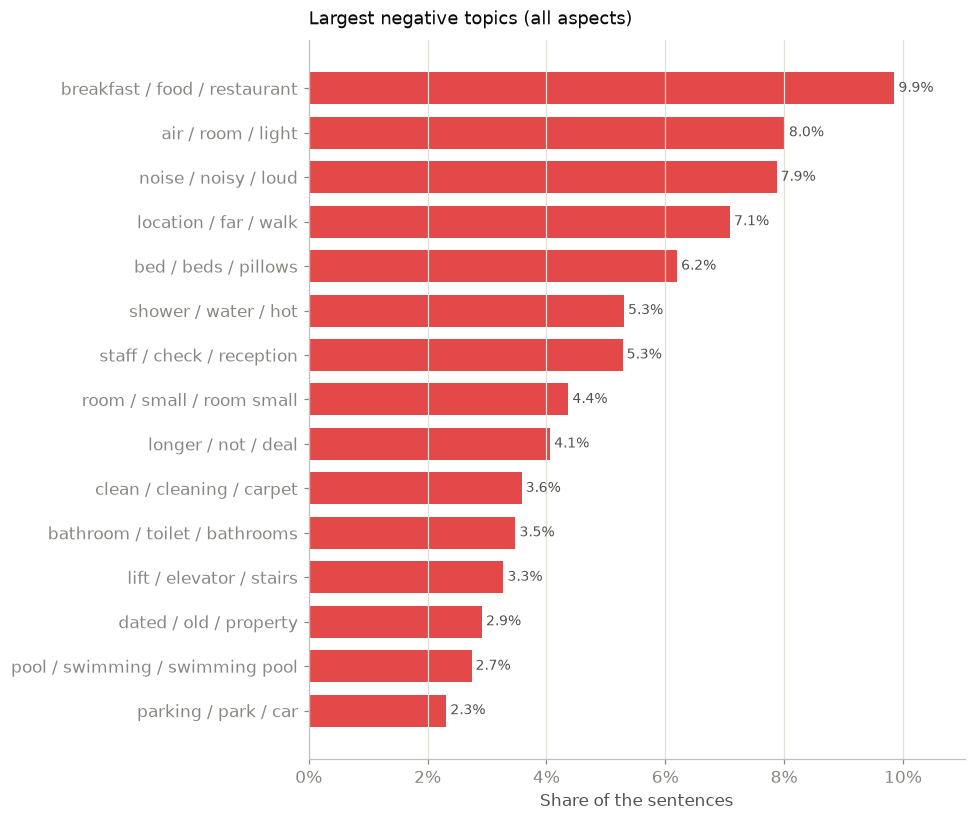

In [7]:
# HU: Áttekintő témamodell az összes ilyen mondaton (mintán) — aspektustól függetlenül.
# EN: Overview topic model on all such sentences (on a sample) — independent of the aspect.
rng = np.random.default_rng(CFG.random_seed)
overview_rows = np.sort(rng.choice(len(subset), size=min(30_000, len(subset)), replace=False))
overview = tm.fit_topics(subset["sentence"].iloc[overview_rows], embeddings[overview_rows])
display(pd.Series(overview.metrics).to_frame("value"))
display(overview.topic_info.head(20))
ev.save_table(overview.topic_info, f"05_{TAG}_topics_overview")
tm.plot_topic_sizes(overview.topic_info, f"Largest {SENTIMENT} topics (all aspects)", sentiment=SENTIMENT,
                    save_as=f"05_{TAG}_topics_overview"); plt.show()

### Finomság-vizsgálat / Granularity sweep

HU: Hány altémára bontsunk egy aspektust? A tapasztalat (v1, v2): egyetlen globális fürtméret nem jó minden
aspektusra — 1%-nál 19–21 apró, egymást átfedő altéma lett (pl. „rooms are small” és „the room was quite small” két
külön fürt), 3%-nál a fürdőszoba 18-ról **2** altémára ugrott (a HDBSCAN egy óriásfürtöt választott). Ezért (v3):
**finom fürtözés, majd a leghasonlóbb altémák összevonása** (BERTopic „topic reduction” elve), amíg legfeljebb
`CFG.subtopic_max_topics` marad, és nincs két `CFG.subtopic_merge_similarity` feletti hasonlóságú (közel-duplikátum)
téma. Az összevonás **átlagos kapcsolással** történik, és egy összevont altéma legfeljebb az aspektus
`CFG.subtopic_max_topic_share` részét (35%) teheti ki — enélkül (v3) „hógolyó” gyűjtőtémák keletkeztek (a zajnál a
forgalom, a zene és a szomszédok egyetlen 55%-os témává olvadt). A táblázat a három legnagyobb aspektuson mutatja a
lehetőségeket (`none` = nincs összevonás). Cél: kb.
**5–10 altéma**, a legnagyobb ≲ 50%, a koherencia (NPMI) ne romoljon. A UMAP aspektusonként egyszer fut (kb. 1–2 perc).

EN: How many subtopics should an aspect be split into? Experience (v1, v2): no single global cluster size suits every
aspect — at 1% there were 19–21 small, overlapping subtopics (e.g. "rooms are small" and "the room was quite small" as
two clusters), at 3% bathroom jumped from 18 to **2** subtopics (HDBSCAN picked one giant cluster). Hence (v3):
**fine clustering, then merging the most similar subtopics** (BERTopic "topic reduction" principle) until at most
`CFG.subtopic_max_topics` remain and no two topics exceed `CFG.subtopic_merge_similarity` (near-duplicates). The table
uses **average linkage**, and a merged subtopic may not exceed `CFG.subtopic_max_topic_share` (35%) of the aspect —
without that (v3) "snowball" catch-all topics appeared (for noise, traffic, music and neighbours melted into one 55%
topic). The table shows the options on the three largest aspects (`none` = no merging). Goal: about **5–10 subtopics**, largest ≲ 50%,
no worse coherence (NPMI). UMAP runs once per aspect (about 1–2 min). Set `RUN_SWEEP = False` once the setting is chosen.

In [8]:
RUN_SWEEP = True
if RUN_SWEEP:
    flag_counts = {a: int(subset[f"asp_{a}"].sum()) for a in ASPECT_NAMES if a not in ("generic",)}
    sweep_aspects = sorted(flag_counts, key=flag_counts.get, reverse=True)[:3]
    sweeps = []
    for aspect in sweep_aspects:
        rows = np.where(subset[f"asp_{aspect}"].to_numpy() == 1)[0]
        rows = np.sort(np.random.default_rng(CFG.random_seed).choice(
            rows, size=min(len(rows), CFG.topic_sample_per_aspect), replace=False))
        sweeps.append(tm.granularity_sweep(subset["sentence"].iloc[rows], embeddings[rows])
                        .reset_index().assign(aspect=aspect))
    sweep = pd.concat(sweeps, ignore_index=True).set_index(["aspect", "min_cluster_share", "max_topics"])
    display(sweep); ev.save_table(sweep, f"05_{TAG}_granularity_sweep")
print("Chosen subtopic settings:", tm.subtopic_params())

c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
18:57:21 | INFO    | src.topic_modeling | Topics: 20 | noise 16.5% -> 7.2% | NPMI 0.074 | diversity 0.805
18:57:25 | INFO    | src.topic_modeling | Topics: 12 | noise 16.5% -> 7.2% | NPMI 0.075 | diversity 0.825
18:57:29 | INFO    | src.topic_modeling | Topics: 10 | noise 16.5% -> 7.2% | NPMI 0.086 | diversity 0.810
18:57:34 | INFO    | src.topic_modeling | Topics: 8 | noise 16.5% -> 7.2% | NPMI 0.059 | diversity 0.787
18:57:38 | INFO    | src.topic_modeling | Topics: 6 | noise 16.5% -> 7.2% | NPMI 0.040 | diversity 0.783
18:57:42 | INFO    | src.topic_modeling | Topics: 16 | noise 17.0% -> 7.6% | NPMI 0.088 | diversity 0.819
18:57:46 | INFO    | src.topic_modeling | Topics: 12 | noise 17.0% -> 7.6% | NPMI 0.081 | diversity 0.817
18:57:50 | INFO    | src.topic_modeling | Topics

min_cluster_size  n_topics_before_merge  n_topics  noise_share_before  mean_coherence_npmi  topic_diversity  \
aspect     min_cluster_share max_topics                                                                                                                
facilities 0.01              none                     150                     20        20              0.1646               0.0742           0.8050   
                             12                       150                     20        12              0.1646               0.0749           0.8250   
                             10                       150                     20        10              0.1646               0.0860           0.8100   
                             8                        150                     20         8              0.1646               0.0594           0.7875   
                             6                        150                     20         6              0.1646               0.0400           0.7833   
           0.02              none                     300                     16        16              0.1701               0.0876           0.8187   
                             12                       300                     16        12              0.1701               0.0807           0.8167   
                             10                       300                     16        10              0.1701               0.1014           0.8000   
                             8                        300                     16         8              0.1701               0.1173           0.8000   
                             6                        300                     16         6              0.1701               0.0823           0.8000   
room       0.01              none                     150                     26        26              0.2257               0.0639           0.7577   
                             12                       150                     26        12              0.2257               0.0470           0.7833   
                             10                       150                     26        10              0.2257               0.0331           0.8000   
                             8                        150                     26         8              0.2257              -0.0018           0.7875   
                             6                        150                     26         6              0.2257               0.0288           0.7667   
           0.02              none                     300                     13        13              0.1410               0.0924           0.7615   
                             12                       300                     13        12              0.1410               0.0879           0.7750   
                             10                       300                     13        10              0.1410               0.0802           0.7500   
                             8                        300                     13         8              0.1410               0.0789           0.7375   
                             6                        300                     13         6              0.1410               0.0609           0.7667   
bathroom   0.01              none                     150                     29        29              0.2164               0.0603           0.7172   
                             12                       150                     29        12              0.2164               0.0772           0.7167   
                             10                       150                     29        10              0.2164               0.0607           0.7300   
                             8                        150                     29         8              0.2164               0.0493           0.7250   
                             6                        150                     29         

19:00:04 | INFO    | src.evaluation | Table saved: 05_negative_full_granularity_sweep.csv


Chosen subtopic settings: {'min_cluster_share': 0.02, 'max_topics': 10, 'merge_similarity': 0.9, 'max_topic_share': 0.35}


19:00:04 | INFO    | src.topic_modeling | room             32238 sentences (model fitted on 15000)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
19:00:28 | INFO    | src.topic_modeling | Topics: 10 | noise 14.1% -> 2.8% | NPMI 0.080 | diversity 0.750
19:00:28 | INFO    | src.topic_modeling | location         13830 sentences (model fitted on 13830)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
19:00:50 | INFO    | src.topic_modeling | Topics: 3 | noise 0.7% -> 0.4% | NPMI 0.051 | diversity 0.767
19:00:50 | INFO    | src.topic_modeling | staff            16416 sentences (model fitted on 15000)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\L

,n_sentences,n_topics_before_merge,n_topics,min_cluster_size,noise_share_before,noise_share_after,mean_coherence_npmi,topic_diversity
aspect,,,,,,,,
room,15000,13,10,300,0.1410,0.0279,0.0802,0.7500
location,13830,3,3,276,0.0072,0.0040,0.0508,0.7667
staff,15000,2,2,300,0.0039,0.0034,0.1119,0.9000
cleanliness,13109,10,10,262,0.1806,0.0259,0.0156,0.7300
facilities,15000,14,10,300,0.1848,0.0851,0.0973,0.8200
comfort,11462,13,10,229,0.2287,0.0104,-0.0126,0.6900
breakfast,15000,12,10,300,0.2549,0.0174,0.0797,0.7600
bathroom,15000,18,10,300,0.2155,0.0067,0.0664,0.7600
noise,15000,3,3,300,0.0335,0.0130,-0.0793,0.7667


19:04:56 | INFO    | src.evaluation | Table saved: 05_negative_full_subtopic_quality.csv
19:04:56 | INFO    | src.evaluation | Table saved: 05_negative_full_subtopics.csv


Main aspects: ['room', 'staff', 'breakfast', 'facilities', 'bathroom', 'noise', 'location', 'cleanliness', 'bed', 'comfort', 'reception', 'value_for_money', 'parking', 'lift', 'pool', 'wifi', 'restaurant', 'view', 'bar', 'beach']


19:05:00 | INFO    | src.evaluation | Figure saved: 05_negative_full_subtopics_by_aspect.png


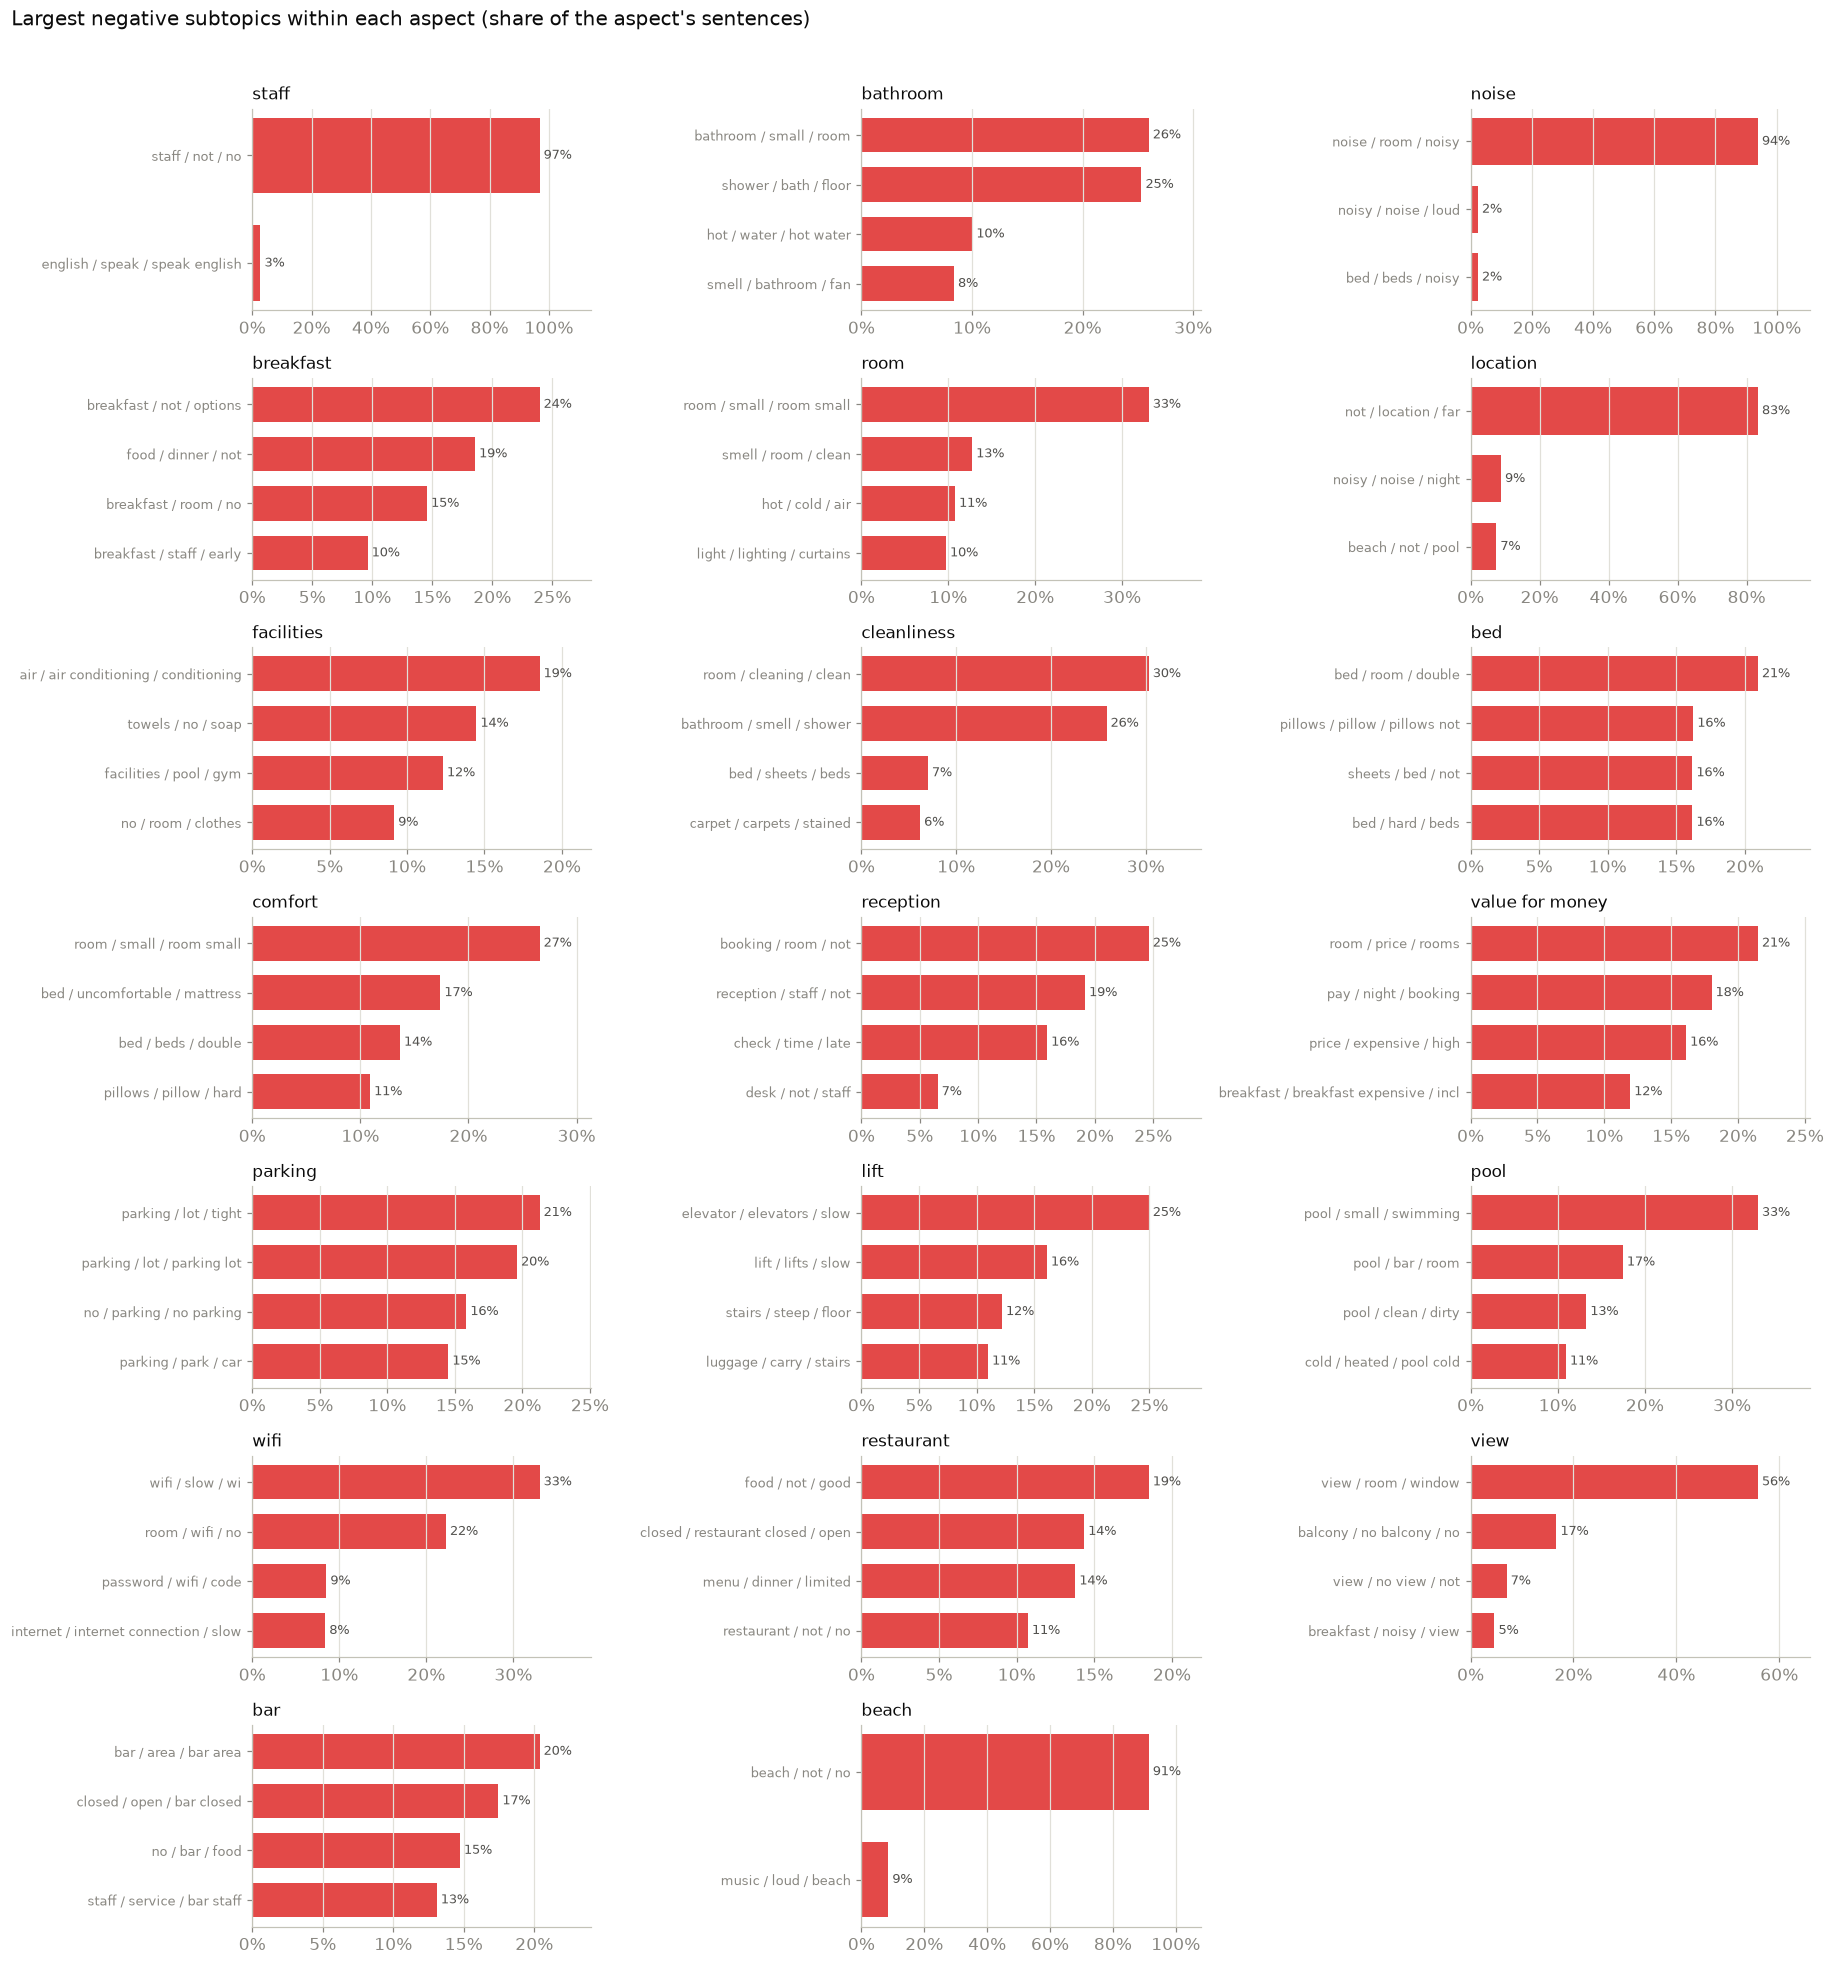

In [9]:
topic_table, assignments, topic_summary = tm.fit_subtopics_per_aspect(subset, embeddings, ASPECT_NAMES)
display(topic_summary)
ev.save_table(topic_summary, f"05_{TAG}_subtopic_quality")
# HU: A legtöbb mondatú, legalább egy altémát adó aspektusok. / EN: Aspects with most sentences and at least one subtopic.
MAIN_ASPECTS = (topic_summary[topic_summary["n_topics"] > 0]
                .sort_values("n_sentences", ascending=False).index.tolist())
print("Main aspects:", MAIN_ASPECTS)
ev.save_table(topic_table, f"05_{TAG}_subtopics")
dl.write_frame(assignments.assign(review_id=subset["review_id"].iloc[assignments["row"]].to_numpy(),
                                  sentence=subset["sentence"].iloc[assignments["row"]].to_numpy()),
               PATHS.labels / f"subtopic_assignments_{TAG}")

tm.plot_aspect_subtopics(topic_table, top_k=4, sentiment=SENTIMENT,
                         save_as=f"05_{TAG}_subtopics_by_aspect"); plt.show()

In [10]:
# HU: Olvasd el az altémákat a példamondatokkal! / EN: Read the subtopics with the example sentences!
for aspect in MAIN_ASPECTS[:4]:
    print(f"\n=== {aspect} ===")
    for _, r in topic_table[topic_table["aspect"] == aspect].head(6).iterrows():
        print(f"  [{r['topic']}] {r['label']}  ({r['share_within_aspect']:.0%}, NPMI {r['coherence_npmi']:.2f})")
        if r["merged_from"]:
            print(f"       merged from: {r['merged_from'][:150]}")
        print(f"       e.g. {r['examples'].split(' || ')[0][:150]}")


=== room ===
  [0] room / small / room small  (33%, NPMI 0.00)
       merged from: small / room / room small + luggage / space / clothes + bathroom / shower / small
       e.g. rooms were quite small
  [1] smell / room / clean  (13%, NPMI 0.02)
       merged from: clean / room / cleaned + smell / smelled / room
       e.g. The room was quite dirty and there were strange smells that we couldn't get rid off even after opening all the windows etc
  [2] hot / cold / air  (11%, NPMI 0.13)
       e.g. there was AC in the room wasn’t working so great so the room was a little warm
  [3] light / lighting / curtains  (10%, NPMI 0.06)
       e.g. If i really need to say something it was that the rooms were a little dark even with the light on
  [4] rooms / dated / furniture  (7%, NPMI -0.01)
       e.g. The rooms need some attention, as decor was old and shabby
  [5] window / windows / open  (7%, NPMI 0.07)
       e.g. no window in room

=== staff ===
  [0] staff / not / no  (97%, NPMI 0.01)
   

In [11]:
# HU: OPCIONÁLIS: beszédes nevek a dolgozatba (a témaszámokat a fenti listából vedd).
# EN: OPTIONAL: meaningful names for the thesis (take the topic numbers from the list above).
TOPIC_NAMES = {
    # ("bathroom", 0): "no hot water",
    # ("noise", 1): "thin walls / neighbours",
}
if TOPIC_NAMES:
    topic_table, assignments = tm.rename_topics(topic_table, assignments, TOPIC_NAMES)
    ev.save_table(topic_table, f"05_{TAG}_subtopics")

### Stabilitás / Stability

HU: Ugyanaz a modell három különböző véletlen kezdőértékkel a három legnagyobb aspektuson. A korrigált Rand-index
(ARI) 0,5 felett azt jelzi, hogy a témák nem a véletlen termékei.
EN: The same model with three different random seeds on the three largest aspects. An adjusted Rand index (ARI)
above 0.5 shows that the topics are not products of chance.

In [12]:
stability_rows = []
for aspect in MAIN_ASPECTS[:3]:
    rows = np.where(subset[f"asp_{aspect}"].to_numpy() == 1)[0]
    rows = np.sort(np.random.default_rng(CFG.random_seed).choice(
        rows, size=min(len(rows), CFG.topic_sample_per_aspect), replace=False))
    table = tm.topic_stability(subset["sentence"].iloc[rows], embeddings[rows], **tm.subtopic_params())
    stability_rows.append({"aspect": aspect, "mean_pairwise_ari": table.attrs["mean_pairwise_ari"],
                           "n_topics_per_seed": table["n_topics"].tolist()})
stability = pd.DataFrame(stability_rows).set_index("aspect").round(3)
display(stability); ev.save_table(stability, f"05_{TAG}_subtopic_stability")

c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
19:05:11 | INFO    | src.topic_modeling | Topics: 10 | noise 14.1% -> 2.8% | NPMI 0.080 | diversity 0.750
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
19:05:21 | INFO    | src.topic_modeling | Topics: 10 | noise 15.6% -> 3.0% | NPMI 0.077 | diversity 0.730
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
19:05:32 | INFO    | src.topic_modeling | Topics: 10 | noise 23.0% -> 3.1% | NPMI 0.085 | diversity 0.770
19:05:32 | INFO    | src.topic_modeling | Stab

,mean_pairwise_ari,n_topics_per_seed
aspect,,
room,0.776,"[10, 10, 10]"
staff,0.195,"[10, 10, 2]"
breakfast,0.707,"[10, 10, 10]"


19:06:31 | INFO    | src.evaluation | Table saved: 05_negative_full_subtopic_stability.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_negative_full_subtopic_stability.csv')

## 5. Panasztérkép / Complaint map

HU: Egy aspektus altémáinak aránya szegmensenként, liftként: 1 felett az altéma az adott szegmensben gyakoribb,
mint átlagosan. Például: a szállodákban a „vékony fal” vagy az apartmanokban a „nincs meleg víz” a jellemzőbb?
Minden cellára arány-z-próba (szegmens vs. többi) Benjamini–Hochberg-korrekcióval. `*` = szignifikáns ÉS legalább 20%-os
eltérés (|lift − 1| ≥ 0,2), halvány = nem. Kis szegmensben a nagy lift is lehet véletlen, nagy mintán pedig egy 1,06-os
eltérés is szignifikáns — a dolgozatban csak a csillagos cellákat értelmezd. Színek: az átlagnál gyakoribb altéma a
szentiment színét kapja (panasz = piros, dicséret = kék), a ritkább szürke.
EN: Share of an aspect's subtopics per segment, as lift: above 1 the subtopic is more common in that segment than on
average. E.g.: is "thin walls" more typical in hotels, or "no hot water" in apartments?
A two-proportion z-test per cell (segment vs. rest) with Benjamini–Hochberg correction. `*` = significant AND at least a
20% difference (|lift − 1| ≥ 0.2), faded = not. In a small segment even a large lift can be chance, on a large sample even
1.06 is significant — interpret only the starred cells in the thesis. Colours: a subtopic more common than average gets
the sentiment colour (complaint = red, praise = blue), a rarer one grey.

19:06:31 | INFO    | src.evaluation | Table saved: 05_negative_full_map_room_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
60,Resort,rooms / dated / furniture,1.931,199,1189,0.0000,True,True
11,Apartment,light / lighting / curtains,1.839,345,2042,0.0000,True,True
15,Apartment,door / lock / key,1.810,182,2042,0.0000,True,True
38,Hostel,noisy / noise / loud,1.693,103,1135,0.0000,True,True
55,Motel,door / lock / key,1.642,78,965,0.0000,True,True
57,Resort,smell / room / clean,1.531,245,1189,0.0000,True,True
7,ApartHotel,door / lock / key,1.469,93,1286,0.0003,True,True
3,ApartHotel,light / lighting / curtains,1.465,173,1286,0.0000,True,True


19:06:33 | INFO    | src.evaluation | Figure saved: 05_negative_full_map_room_by_accommodation_type.png


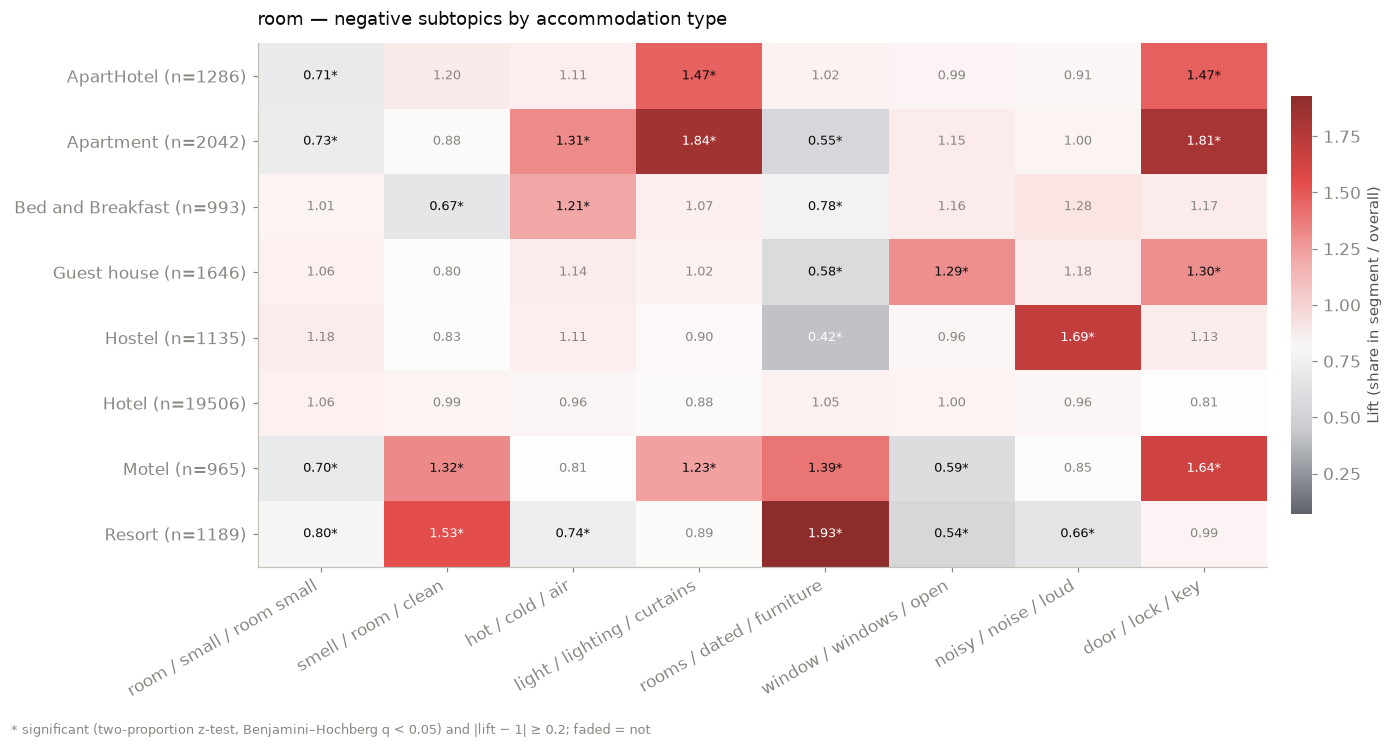

19:06:33 | INFO    | src.evaluation | Table saved: 05_negative_full_map_room_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
24,Japan,room / small / room small,1.851,610,1009,0.0000,True,True
41,Thailand,smell / room / clean,1.707,140,634,0.0000,True,True
57,United States of America,smell / room / clean,1.646,847,3980,0.0000,True,True
3,Australia,light / lighting / curtains,1.547,237,1628,0.0000,True,True
8,France,room / small / room small,1.406,562,1224,0.0000,True,True
7,Australia,door / lock / key,1.378,115,1628,0.0005,True,True
4,Australia,rooms / dated / furniture,1.368,194,1628,0.0000,True,True
38,Spain,noisy / noise / loud,1.360,90,1229,0.0041,True,True


19:06:34 | INFO    | src.evaluation | Figure saved: 05_negative_full_map_room_by_accommodation_country.png


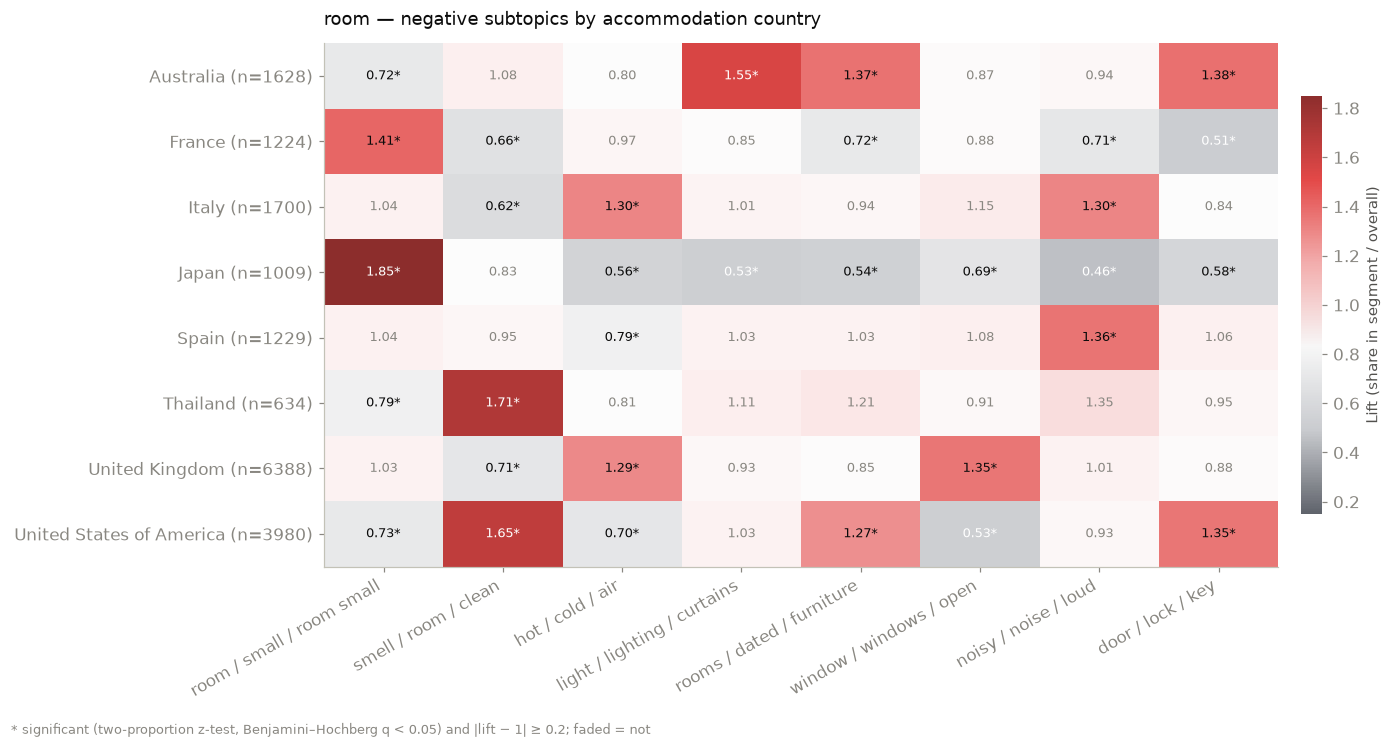

19:06:34 | INFO    | src.evaluation | Table saved: 05_negative_full_map_staff_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
5,Bed and Breakfast,english / speak / speak english,1.709,20,402,0.0466,True,True
7,Guest house,english / speak / speak english,1.525,29,653,0.0466,True,True
13,Motel,english / speak / speak english,0.203,2,338,0.0466,True,True


19:06:35 | INFO    | src.evaluation | Figure saved: 05_negative_full_map_staff_by_accommodation_type.png


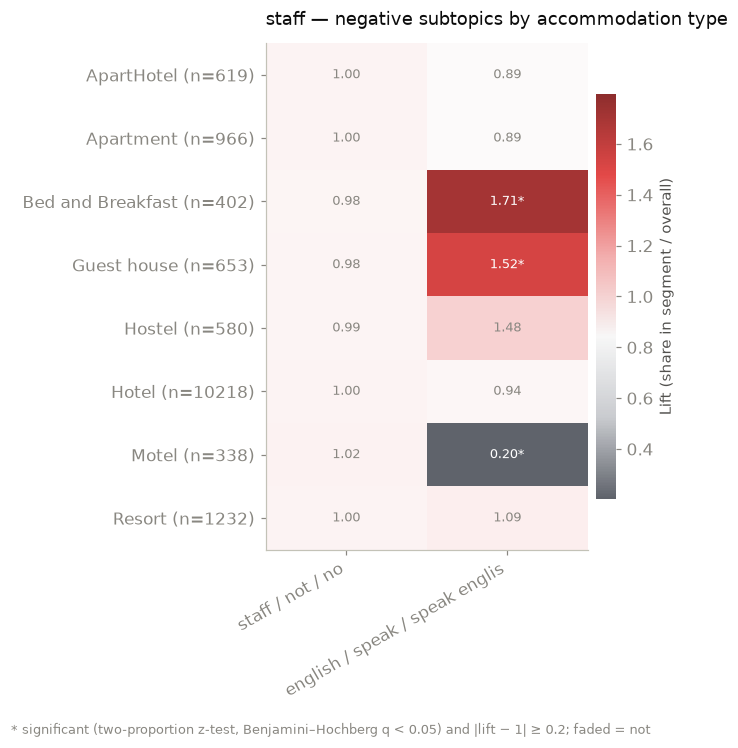

19:06:35 | INFO    | src.evaluation | Table saved: 05_negative_full_map_staff_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
11,Thailand,english / speak / speak english,3.977,42,573,0.0000,True,True
9,Spain,english / speak / speak english,2.699,30,603,0.0000,True,True
7,Italy,english / speak / speak english,2.119,30,768,0.0000,True,True
15,United States of America,english / speak / speak english,0.439,21,2598,0.0000,True,True
1,Australia,english / speak / speak english,0.420,5,646,0.0477,True,True
13,United Kingdom,english / speak / speak english,0.291,15,2799,0.0000,True,True


19:06:36 | INFO    | src.evaluation | Figure saved: 05_negative_full_map_staff_by_accommodation_country.png


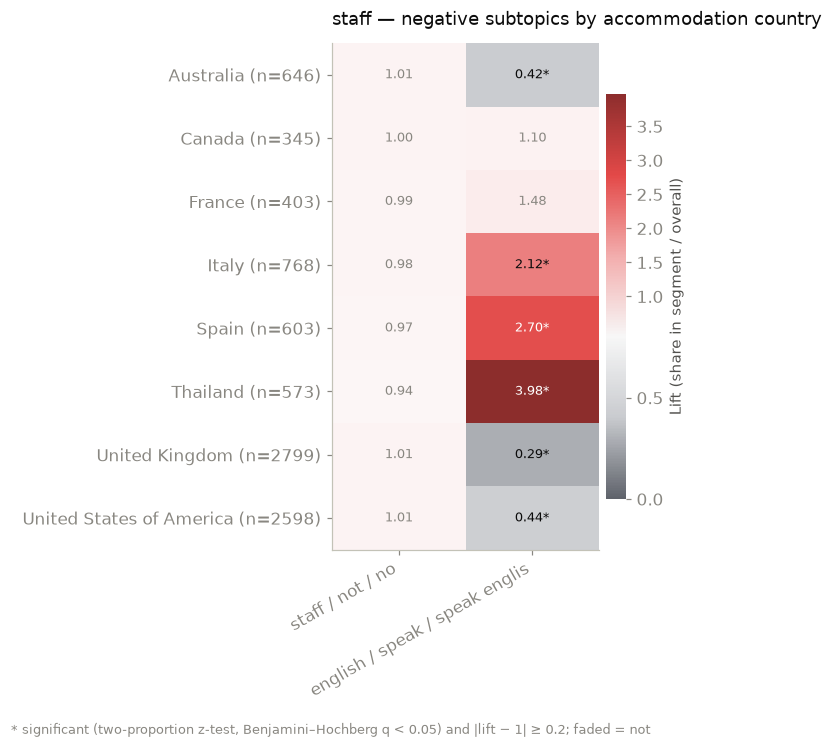

19:06:36 | INFO    | src.evaluation | Table saved: 05_negative_full_map_breakfast_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
13,Apartment,coffee / tea / milk,2.462,50,289,0.0000,True,True
57,Resort,food / dinner / not,2.139,361,912,0.0000,True,True
46,Inn,eggs / bacon / scrambled,1.798,32,310,0.0021,True,True
47,Inn,fruit / fresh / juice,1.723,23,310,0.0239,True,True
48,Motel,breakfast / not / options,1.662,95,234,0.0000,True,True
19,Bed and Breakfast,breakfast / staff / early,1.605,98,623,0.0000,True,True
27,Guest house,breakfast / staff / early,1.463,67,467,0.0034,True,True
42,Inn,breakfast / room / no,0.671,31,310,0.0416,True,True


19:06:37 | INFO    | src.evaluation | Figure saved: 05_negative_full_map_breakfast_by_accommodation_type.png


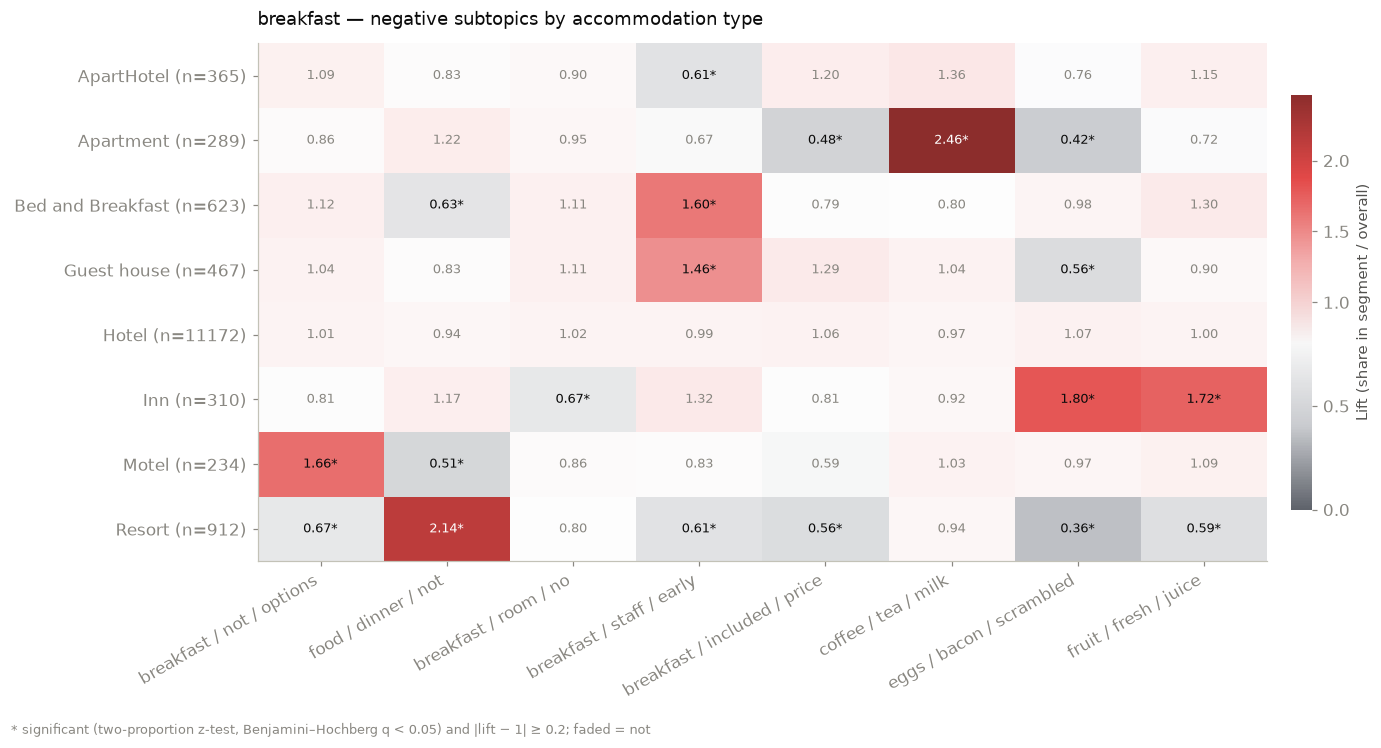

19:06:38 | INFO    | src.evaluation | Table saved: 05_negative_full_map_breakfast_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
12,France,breakfast / included / price,1.840,70,485,0.0000,True,True
5,Australia,coffee / tea / milk,1.637,49,414,0.0008,True,True
1,Australia,food / dinner / not,1.538,113,414,0.0000,True,True
33,Spain,food / dinner / not,1.476,148,565,0.0000,True,True
37,Spain,coffee / tea / milk,1.371,56,565,0.0282,True,True
56,United States of America,breakfast / not / options,1.324,767,2420,0.0000,True,True
24,Italy,breakfast / not / options,1.313,253,805,0.0000,True,True
40,Thailand,breakfast / not / options,1.306,161,515,0.0003,True,True


19:06:39 | INFO    | src.evaluation | Figure saved: 05_negative_full_map_breakfast_by_accommodation_country.png


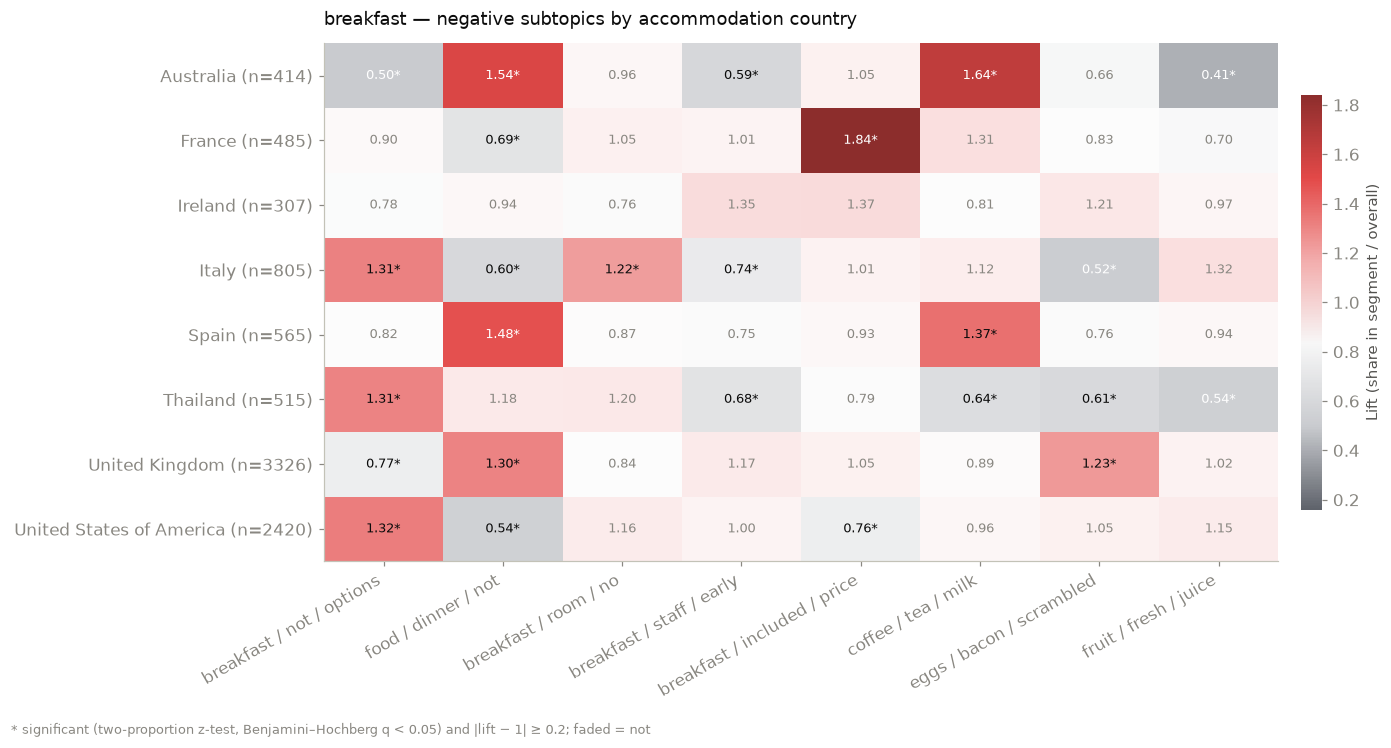

In [13]:
for aspect in MAIN_ASPECTS[:3]:
    for segment in ["accommodation_type", "accommodation_country"]:
        lift = tm.segment_table(assignments, subset, aspect, segment, min_count=50, top_segments=8)
        if lift.empty:
            continue
        long = tm.segment_long_table(lift)
        ev.save_table(long, f"05_{TAG}_map_{aspect}_by_{segment}")
        display(long[long["notable"]].head(8))
        tm.plot_segment_heatmap(lift, f"{aspect.replace('_', ' ')} — {SENTIMENT} subtopics by {segment.replace('_', ' ')}",
                                save_as=f"05_{TAG}_map_{aspect}_by_{segment}", sentiment=SENTIMENT)
        plt.show()

## 6. Kézi ellenőrzés / Manual check

HU: Témánként 20 véletlen mondat Excelben; a `fits` oszlopba 1 (illik a témához) vagy 0 kerül. Az első futás
exportál, a kitöltés után a második futás kiszámolja a témánkénti pontosságot. (Kb. 1–2 óra a nagyobb aspektusokra.)
EN: 20 random sentences per topic in Excel; put 1 (fits the topic) or 0 into the `fits` column. The first run exports,
after filling it in the second run computes the per-topic precision. (About 1–2 hours for the larger aspects.)

In [14]:
check_file = PATHS.annotation / f"topic_check_{TAG}.xlsx"
if not check_file.exists():
    top_aspects = MAIN_ASPECTS[:4]
    tm.export_topic_check(topic_table[topic_table["aspect"].isin(top_aspects)],
                          assignments[assignments["aspect"].isin(top_aspects)], subset,
                          filename=check_file.name)
    print("Exported — fill in the 'fits' column, then re-run this cell.")
else:
    precision = tm.evaluate_topic_check(check_file.name)
    display(precision); ev.save_table(precision, f"05_{TAG}_topic_precision")

19:06:40 | INFO    | src.topic_modeling | Topic check exported: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\data\annotation\topic_check_negative_full.xlsx (640 sentences)


Exported — fill in the 'fits' column, then re-run this cell.


---
## Összefoglalás / Summary

| Kimenet / Output | Mire jó? / Purpose |
|---|---|
| `05_aspect_keyword_vs_model` (tábla + ábra) | **2/a mérése:** tanult modell vs. kulcsszólista, emberi címkén |
| `05_aspect_model_test_report` | aspektusonkénti precision / recall / F1 |
| `05_aspect_sentiment_model` | aspektus × szentiment a tanult aspektusokkal |
| `05_<sentiment>_<verzió>_removed_non_complaints` | kiszűrt nem-panasz egységek („nothing”, „all good”) |
| `05_<sentiment>_<verzió>_granularity_sweep` | az altéma-finomság (fürtméret × összevonás) választásának indoklása |
| `05_<sentiment>_<verzió>_subtopics` + `_subtopics_by_aspect.png` | **2/b:** altémák aspektusonként |
| `05_<sentiment>_<verzió>_subtopic_quality`, `_stability` | koherencia, diverzitás, stabilitás |
| `05_<sentiment>_<verzió>_map_*` | **panasztérkép** szegmensenként (a 8 legnagyobb altéma; db, lift, q, szignifikáns, jelentős) |
| `05_<sentiment>_<verzió>_topic_precision` | kézi ellenőrzés: témánkénti pontosság |

HU: A `<verzió>` = `CFG.topic_version` (most `v5`). A régebbi, verzió nélküli `05_negative_*` fájlok a v1 futás
eredményei — a dolgozat 3.4 fejezetében az előtte–utána összevetéshez hasznosak.
EN: `<verzió>` = `CFG.topic_version` (now `v5`). The older `05_negative_*` files without a version are the results of
run v1 — useful for the before/after comparison in chapter 3.4.